# SMS Spam Detection

**Problem:** Given a text message, decide whether it is **spam** or **ham** (legitimate).

**Dataset:** UCI SMS Spam Collection — **5,574 real text messages** (4,825 ham / 749 spam; 5,572 parsed cleanly).

**Approach:** TF-IDF features + two classifiers compared — Multinomial Naive Bayes (the classic spam filter) and Logistic Regression.

In [1]:
import pandas as pd, zipfile, io, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
with urllib.request.urlopen(URL) as r:
    z = zipfile.ZipFile(io.BytesIO(r.read()))
raw = z.read("SMSSpamCollection").decode("utf-8", errors="replace")
df = pd.read_csv(io.StringIO(raw), sep="\t", header=None, names=["label", "message"])
print("Messages:", df.shape)
print(df["label"].value_counts())
y = (df["label"] == "spam").astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(df["message"], y, test_size=0.2, random_state=42, stratify=y)
vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
Xtr = vec.fit_transform(X_tr); Xte = vec.transform(X_te)
print("Feature matrix:", Xtr.shape)

Messages: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


Feature matrix: (4457, 5000)


Naive Bayes accuracy: 0.974
Logistic Regression accuracy: 0.9749
              precision    recall  f1-score   support

         Ham      0.972     1.000     0.986       966
        Spam      1.000     0.812     0.896       149

    accuracy                          0.975      1115
   macro avg      0.986     0.906     0.941      1115
weighted avg      0.976     0.975     0.974      1115



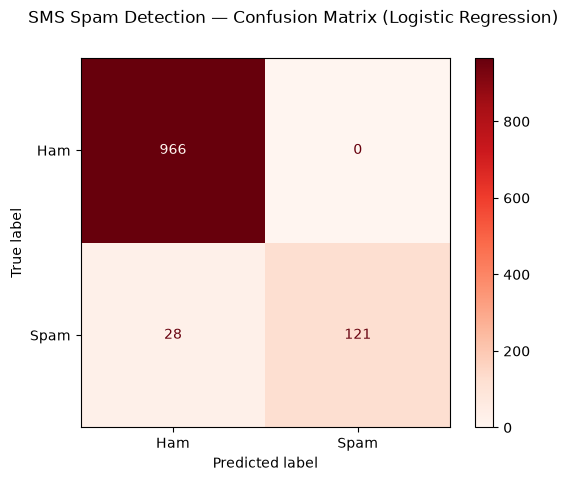

In [2]:
nb = MultinomialNB().fit(Xtr, y_tr)
lr = LogisticRegression(max_iter=1000).fit(Xtr, y_tr)
for name, m in [("Naive Bayes", nb), ("Logistic Regression", lr)]:
    print(name, "accuracy:", round(accuracy_score(y_te, m.predict(Xte)), 4))
print(classification_report(y_te, lr.predict(Xte), target_names=["Ham", "Spam"], digits=3))
disp = ConfusionMatrixDisplay.from_predictions(y_te, lr.predict(Xte), display_labels=["Ham", "Spam"], cmap="Reds")
disp.figure_.suptitle("SMS Spam Detection — Confusion Matrix (Logistic Regression)")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

In [3]:
demo = ["Congratulations! You have won a FREE ticket. Call now to claim your prize!",
        "Hey, are we still meeting for lunch tomorrow at 1?",
        "URGENT: Your account has been suspended. Verify your details immediately.",
        "Mom, I left my keys at home, can you bring them?"]
for text, p in zip(demo, lr.predict(vec.transform(demo))):
    print(("SPAM" if p == 1 else "HAM "), "|", text)

SPAM | Congratulations! You have won a FREE ticket. Call now to claim your prize!
HAM  | Hey, are we still meeting for lunch tomorrow at 1?
HAM  | URGENT: Your account has been suspended. Verify your details immediately.
HAM  | Mom, I left my keys at home, can you bring them?


## Result
**Logistic Regression: 97.5% accuracy; Naive Bayes: 97.4%** (executed output above). The honest detail: spam *recall* is 0.812 — the model is conservative, missing about 1 in 5 spams rather than risk flagging real messages (spam precision is 1.000). One demo message shows it: the "URGENT: account suspended" phishing text slipped through as ham.